# How are in-demand skills trending for Data Analyst?

## Logic : 
### 1. Aggregate skill counts monthly
### 2. Re-Analyse based on percentage of total jobs
### 3. Plot the monthly skill demand 



In [41]:

import ast
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt
from adjustText import adjust_text
import seaborn as sns

dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x:ast.literal_eval(x) if pd.notna(x) else x)


In [42]:
df_DA_IN = df[(df['job_title'] == 'Data Analyst') & (df['job_country']=='India')].copy()
df_DA_IN.sample(5)

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
659720,Data Analyst,Data Analyst,"Hyderabad, Telangana, India",via BeBee India,Full-time,False,India,2023-01-02 10:25:20,True,False,India,NaN,NaN,NaN,Fusion Plus Solutions Inc,"[sql, python, aws, tableau]","{'analyst_tools': ['tableau'], 'cloud': ['aws'..."
30699,Data Analyst,Data Analyst,India,via BeBee India,Full-time,False,India,2023-11-30 13:12:14,False,False,India,NaN,NaN,NaN,TEKnuova,"[sql, excel, tableau, power bi]","{'analyst_tools': ['excel', 'tableau', 'power ..."
661801,Data Analyst,Data Analyst,India,via LinkedIn,Full-time,False,India,2023-02-14 10:26:48,False,False,India,NaN,NaN,NaN,"Apollo Global Management, Inc.","[sql, power bi]","{'analyst_tools': ['power bi'], 'programming':..."
55204,Data Analyst,Data Analyst,"Hyderabad, Telangana, India",via BeBee India,Full-time,False,India,2023-02-06 06:14:12,True,False,India,NaN,NaN,NaN,GlobalData Plc,"[python, vba, pandas, scikit-learn, excel]","{'analyst_tools': ['excel'], 'libraries': ['pa..."
31530,Data Analyst,Data Analyst,India,via BeBee India,Full-time,False,India,2023-10-25 13:12:44,False,False,India,NaN,NaN,NaN,Highlevel Llc,"[sql, excel, tableau, looker]","{'analyst_tools': ['excel', 'tableau', 'looker..."


In [43]:
df_DA_IN['job_posted_month_no'] = df_DA_IN['job_posted_date'].dt.month
df_DA_IN_explode = df_DA_IN.explode('job_skills')
df_DA_IN_explode[['job_title_short','job_skills']].sample(5)

,job_title_short,job_skills
636331,Data Analyst,sql
365799,Data Analyst,sql
413073,Data Analyst,tableau
159752,Data Analyst,power bi
123639,Data Analyst,aws


In [44]:
df_DA_IN_pivot = df_DA_IN_explode.pivot_table(
    index = 'job_posted_month_no',
    columns = 'job_skills',
    aggfunc = 'size',
    fill_value= 0
)

df_DA_IN_pivot.loc['Total'] = df_DA_IN_pivot.sum()

df_DA_IN_pivot= df_DA_IN_pivot[df_DA_IN_pivot.loc['Total'].sort_values(ascending = False).index]

df_DA_IN_pivot= df_DA_IN_pivot.drop('Total')

df_DA_IN_pivot


job_skills,sql,python,excel,tableau,power bi,sas,r,aws,azure,javascript,...,react.js,swift,ringcentral,suse,jupyter,sqlite,ggplot2,gitlab,graphql,no-sql
job_posted_month_no,,,,,,,,,,,,,,,,,,,,,
1,75,55,51,41,26,36,23,6,5,11,...,0,0,0,0,0,0,0,0,1,0
2,64,40,46,32,24,14,23,6,7,8,...,0,0,0,0,0,0,1,0,0,0
3,57,25,32,30,19,10,9,7,6,3,...,0,1,0,1,0,0,0,0,0,1
4,56,35,35,27,23,24,16,4,8,7,...,1,0,0,0,0,0,0,1,0,0
5,44,25,37,24,18,10,9,4,9,3,...,0,0,0,0,0,0,0,0,0,0
6,50,42,34,29,23,28,23,10,9,5,...,0,0,0,0,0,0,0,0,0,0
7,57,37,37,38,20,20,23,5,8,5,...,0,0,0,0,0,0,0,0,0,0
8,88,58,54,47,43,24,28,20,11,7,...,0,0,0,0,0,0,0,0,0,0
9,96,65,59,53,43,26,27,12,5,14,...,0,0,0,0,1,0,0,0,0,0


In [45]:
DA_totals = df_DA_IN.groupby('job_posted_month_no').size()
DA_totals

job_posted_month_no
1     144
2     118
3      97
4      99
5      64
6      93
7      92
8     141
9     166
10    126
11    204
12    195
dtype: int64

In [46]:
df_DA_IN_percent = df_DA_IN_pivot.div(DA_totals/100,axis=0)
df_DA_IN_percent

job_skills,sql,python,excel,tableau,power bi,sas,r,aws,azure,javascript,...,react.js,swift,ringcentral,suse,jupyter,sqlite,ggplot2,gitlab,graphql,no-sql
job_posted_month_no,,,,,,,,,,,,,,,,,,,,,
1,52.083333,38.194444,35.416667,28.472222,18.055556,25.000000,15.972222,4.166667,3.472222,7.638889,...,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.694444,0.000000
2,54.237288,33.898305,38.983051,27.118644,20.338983,11.864407,19.491525,5.084746,5.932203,6.779661,...,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.847458,0.000000,0.000000,0.000000
3,58.762887,25.773196,32.989691,30.927835,19.587629,10.309278,9.278351,7.216495,6.185567,3.092784,...,0.000000,1.030928,0.000000,1.030928,0.00000,0.000000,0.000000,0.000000,0.000000,1.030928
4,56.565657,35.353535,35.353535,27.272727,23.232323,24.242424,16.161616,4.040404,8.080808,7.070707,...,1.010101,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,1.010101,0.000000,0.000000
5,68.750000,39.062500,57.812500,37.500000,28.125000,15.625000,14.062500,6.250000,14.062500,4.687500,...,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000
6,53.763441,45.161290,36.559140,31.182796,24.731183,30.107527,24.731183,10.752688,9.677419,5.376344,...,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000
7,61.956522,40.217391,40.217391,41.304348,21.739130,21.739130,25.000000,5.434783,8.695652,5.434783,...,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000
8,62.411348,41.134752,38.297872,33.333333,30.496454,17.021277,19.858156,14.184397,7.801418,4.964539,...,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000
9,57.831325,39.156627,35.542169,31.927711,25.903614,15.662651,16.265060,7.228916,3.012048,8.433735,...,0.000000,0.000000,0.000000,0.000000,0.60241,0.000000,0.000000,0.000000,0.000000,0.000000


In [ ]:
#Change to months format 
df_DA_IN_percent =  df_DA_IN_percent.reset_index()

df_DA_IN_percent['job_posted_month'] = df_DA_IN_percent['job_posted_month_no'].apply(
    lambda x: pd.to_datetime(str(x), format='%m').strftime('%b')
)
df_DA_IN_percent = df_DA_IN_percent.set_index('job_posted_month')
df_DA_IN_percent = df_DA_IN_percent.drop(columns='job_posted_month_no')

df_DA_IN_percent



job_skills,sql,python,excel,tableau,power bi,sas,r,aws,azure,javascript,...,react.js,swift,ringcentral,suse,jupyter,sqlite,ggplot2,gitlab,graphql,no-sql
job_posted_month,,,,,,,,,,,,,,,,,,,,,
Jan,52.083333,38.194444,35.416667,28.472222,18.055556,25.000000,15.972222,4.166667,3.472222,7.638889,...,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.694444,0.000000
Feb,54.237288,33.898305,38.983051,27.118644,20.338983,11.864407,19.491525,5.084746,5.932203,6.779661,...,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.847458,0.000000,0.000000,0.000000
Mar,58.762887,25.773196,32.989691,30.927835,19.587629,10.309278,9.278351,7.216495,6.185567,3.092784,...,0.000000,1.030928,0.000000,1.030928,0.00000,0.000000,0.000000,0.000000,0.000000,1.030928
Apr,56.565657,35.353535,35.353535,27.272727,23.232323,24.242424,16.161616,4.040404,8.080808,7.070707,...,1.010101,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,1.010101,0.000000,0.000000
May,68.750000,39.062500,57.812500,37.500000,28.125000,15.625000,14.062500,6.250000,14.062500,4.687500,...,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000
Jun,53.763441,45.161290,36.559140,31.182796,24.731183,30.107527,24.731183,10.752688,9.677419,5.376344,...,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000
Jul,61.956522,40.217391,40.217391,41.304348,21.739130,21.739130,25.000000,5.434783,8.695652,5.434783,...,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000
Aug,62.411348,41.134752,38.297872,33.333333,30.496454,17.021277,19.858156,14.184397,7.801418,4.964539,...,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000
Sep,57.831325,39.156627,35.542169,31.927711,25.903614,15.662651,16.265060,7.228916,3.012048,8.433735,...,0.000000,0.000000,0.000000,0.000000,0.60241,0.000000,0.000000,0.000000,0.000000,0.000000


In [52]:
df_plot = df_DA_IN_percent.iloc[:, :5]
df_plot


job_skills,sql,python,excel,tableau,power bi
job_posted_month,,,,,
Jan,52.083333,38.194444,35.416667,28.472222,18.055556
Feb,54.237288,33.898305,38.983051,27.118644,20.338983
Mar,58.762887,25.773196,32.989691,30.927835,19.587629
Apr,56.565657,35.353535,35.353535,27.272727,23.232323
May,68.750000,39.062500,57.812500,37.500000,28.125000
Jun,53.763441,45.161290,36.559140,31.182796,24.731183
Jul,61.956522,40.217391,40.217391,41.304348,21.739130
Aug,62.411348,41.134752,38.297872,33.333333,30.496454
Sep,57.831325,39.156627,35.542169,31.927711,25.903614


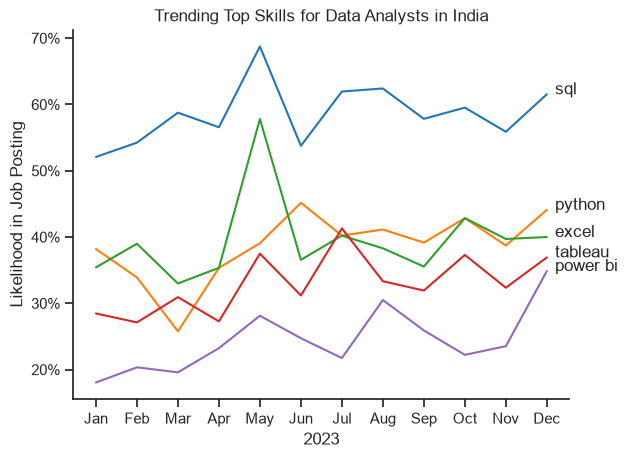

In [ ]:

sns.lineplot(data=df_plot,dashes=False,palette='tab10',legend=False)
sns.set_theme(style='ticks')
sns.despine()

plt.title('Trending Top Skills for Data Analysts in India')
plt.ylabel('Likelihood in Job Posting')
plt.xlabel('2023')

plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f'{x:.0f}%')
)


for i in range(5):
    plt.text(11.2,df_plot.iloc[-1,i], df_plot.columns[i])

    